# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Frisca Angellita
- **Email:** frisca.angel18@gmail.com
- **ID Dicoding:** frisca_angellita

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Konteks bisnis.** Dataset ini berisi transaksi marketplace Brasil (Olist). Data transaksi yang lengkap tersedia pada **Januari 2017 – Agustus 2018**, sehingga seluruh pertanyaan dibatasi pada periode itu dan hanya memakai order berstatus `delivered`. **Revenue** didefinisikan sebagai jumlah `price` item (tidak termasuk ongkos kirim). Anggaplah kita tim analitik marketplace yang perlu memutuskan **kategori apa yang diprioritaskan, kapan menyiapkan kampanye, wilayah mana yang logistiknya diperbaiki, dan pelanggan mana yang ditarget kampanye retensi**.

| # | Pertanyaan | S | M | A | R | T |
|---|---|---|---|---|---|---|
| 1 | Kategori produk | Kontribusi revenue per kategori | Revenue (R$) dan % kontribusi, top 10 dan bottom 5 | Menentukan kategori prioritas stok dan promosi | Fokus bisnis pada kategori berkontribusi besar | Jan 2017 – Agu 2018 |
| 2 | Tren bulanan | Order dan revenue per bulan | Jumlah order, revenue, pertumbuhan MoM (%) | Merencanakan kapasitas dan kampanye musiman | Pertumbuhan penjualan adalah tujuan utama | Jan 2017 – Agu 2018 |
| 3 | State dan pengiriman | Revenue, keterlambatan, dan review per state | Revenue (R$), % order terlambat, rata-rata review (1-5) | Menentukan wilayah prioritas perbaikan logistik | Pengiriman memengaruhi kepuasan dan repeat order | Jan 2017 – Agu 2018 |
| 4 | Segmentasi pelanggan | Pelanggan unik berdasarkan RFM | Jumlah pelanggan dan % revenue per segmen | Menentukan target retensi dan reaktivasi | Sebagian besar pelanggan tidak repeat order | Per 30 Agustus 2018 |

- **Pertanyaan 1:** Kategori produk apa saja yang menjadi 10 penyumbang revenue terbesar dan 5 terendah selama Januari 2017 – Agustus 2018, dan berapa persen kontribusinya terhadap total revenue?
- **Pertanyaan 2:** Bagaimana tren jumlah order dan total revenue bulanan selama Januari 2017 – Agustus 2018, berapa pertumbuhan Month-over-Month (MoM), dan bulan mana yang mencapai puncak?
- **Pertanyaan 3:** Negara bagian (state) mana yang menyumbang revenue terbesar selama Januari 2017 – Agustus 2018, berapa persentase order terlambat dan rata-rata review score di tiap state, dan seberapa besar keterlambatan menurunkan review score?
- **Pertanyaan 4:** Bagaimana segmentasi pelanggan berdasarkan RFM (Recency, Frequency, Monetary) per 30 Agustus 2018, berapa proporsi pelanggan dan kontribusi revenue tiap segmen?

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import sys
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

#### Persiapan lokasi data (otomatis untuk Google Colab)
Notebook membaca berkas dari folder `data/`. Sel di bawah ini memeriksa apakah folder tersebut sudah ada:
- **Di komputer sendiri** (Jupyter/VS Code): jalankan notebook dari folder `submission`, sel ini tidak melakukan apa-apa.
- **Di Google Colab**: jika folder `data/` belum ada, sel ini meminta Anda mengunggah `submission.zip`, lalu mengekstraknya otomatis.

In [2]:
if not os.path.isdir("data") and "google.colab" in sys.modules:
    from google.colab import files
    print("Folder data/ belum ada. Unggah berkas submission.zip (±53 MB), tunggu sampai 100%.")
    uploaded = files.upload()
    for name in uploaded:
        if name.endswith(".zip"):
            zipfile.ZipFile(name).extractall(".")
    if os.path.isdir("submission"):
        os.chdir("submission")

assert os.path.isdir("data"), "Folder data/ tidak ditemukan. Jalankan notebook dari folder 'submission'."
print("Folder kerja:", os.getcwd())
print("Berkas data :", sorted(os.listdir("data")))

Folder data/ belum ada. Unggah berkas submission.zip (±53 MB), tunggu sampai 100%.


Saving submission.zip to submission.zip
Folder kerja: /content/submission
Berkas data : ['customers_dataset.csv', 'geolocation_dataset.csv', 'order_items_dataset.csv', 'order_payments_dataset.csv', 'order_reviews_dataset.csv', 'orders_dataset.csv', 'product_category_name_translation.csv', 'products_dataset.csv', 'sellers_dataset.csv']


## Data Wrangling

### Gathering Data

Sembilan berkas CSV dimuat ke dalam DataFrame. Kolom tanggal pada tabel `orders` langsung diubah ke tipe `datetime`.

#### Load df orders, order_items, customers, products, reviews, payments, sellers, dan geolocation

In [3]:
DATA_DIR = "data"
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]

orders_df    = pd.read_csv(f"{DATA_DIR}/orders_dataset.csv", parse_dates=date_cols)
items_df     = pd.read_csv(f"{DATA_DIR}/order_items_dataset.csv")
customers_df = pd.read_csv(f"{DATA_DIR}/customers_dataset.csv")
products_df  = pd.read_csv(f"{DATA_DIR}/products_dataset.csv")
category_df  = pd.read_csv(f"{DATA_DIR}/product_category_name_translation.csv")
reviews_df   = pd.read_csv(f"{DATA_DIR}/order_reviews_dataset.csv")
payments_df  = pd.read_csv(f"{DATA_DIR}/order_payments_dataset.csv")
sellers_df   = pd.read_csv(f"{DATA_DIR}/sellers_dataset.csv")
geo_df       = pd.read_csv(f"{DATA_DIR}/geolocation_dataset.csv")

tables = {"orders": orders_df, "order_items": items_df, "customers": customers_df, "products": products_df,
          "category_translation": category_df, "reviews": reviews_df, "payments": payments_df,
          "sellers": sellers_df, "geolocation": geo_df}
pd.DataFrame({k: v.shape for k, v in tables.items()}, index=["baris", "kolom"]).T

,baris,kolom
orders,99441,8
order_items,112650,7
customers,99441,5
products,32951,9
category_translation,71,2
reviews,99224,7
payments,103886,5
sellers,3095,4
geolocation,1000163,5


In [4]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [5]:
items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


**Insight:**
- Tabel `orders` (99.441 baris) menjadi tabel pusat; `order_items` (112.650 baris) menghubungkan order ke produk dan penjual, sedangkan `customers` menghubungkan order ke pelanggan beserta lokasinya.
- `customer_id` bersifat unik **per order**, sedangkan orang yang sama diidentifikasi oleh `customer_unique_id`. Ini penting untuk analisis RFM.
- Tabel `geolocation` sangat besar (1 juta baris) sehingga perlu diringkas sebelum dipakai.

### Assessing Data

Setiap tabel diperiksa untuk menemukan *missing value*, data duplikat, nilai tidak valid, ketidakkonsistenan, dan *outlier*.

#### Identifying missing value & duplicate data problem

In [6]:
for name in ["orders", "products", "reviews", "customers"]:
    df_ = tables[name]
    miss = df_.isna().sum()
    print(f"== {name}: {df_.shape[0]} baris | duplikat: {df_.duplicated().sum()}")
    print(miss[miss > 0].to_string() if miss.sum() else "tidak ada missing value", "\n")

== orders: 99441 baris | duplikat: 0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965 

== products: 32951 baris | duplikat: 0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2 

== reviews: 99224 baris | duplikat: 0
review_comment_title      87656
review_comment_message    58247 

== customers: 99441 baris | duplikat: 0
tidak ada missing value 



#### Identifying inconsistent value problem (status order dan periode data)

In [7]:
print(orders_df["order_status"].value_counts().to_string())
print()
print(orders_df["order_purchase_timestamp"].dt.to_period("M").value_counts().sort_index().to_string())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M


#### Identifying invalid & inaccurate value problem (tanggal kosong, terjemahan kategori, review ganda, geolokasi)

In [8]:
# Order 'delivered' tetapi tanggal diterima pelanggan kosong
print("delivered tanpa tanggal diterima:",
      ((orders_df["order_status"] == "delivered") & orders_df["order_delivered_customer_date"].isna()).sum())

# Kategori produk tanpa terjemahan bahasa Inggris
missing_trans = set(products_df["product_category_name"].dropna()) - set(category_df["product_category_name"])
print("kategori tanpa terjemahan:", missing_trans)

# Review: satu order bisa memiliki lebih dari satu review
print("order dengan >1 review:", reviews_df["order_id"].duplicated().sum())

# Geolocation: duplikat dan koordinat di luar wilayah Brasil
print("geolocation duplikat:", geo_df.duplicated().sum())
outside = ~geo_df["geolocation_lat"].between(-33.75, 5.27) | ~geo_df["geolocation_lng"].between(-73.99, -34.79)
print("koordinat di luar Brasil:", outside.sum())

delivered tanpa tanggal diterima: 8
kategori tanpa terjemahan: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}
order dengan >1 review: 551
geolocation duplikat: 261831
koordinat di luar Brasil: 42


#### Identifying outlier problem (metode IQR)

In [9]:
def count_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    return pd.Series({"median": s.median(), "batas_atas_IQR": upper, "maksimum": s.max(),
                      "jumlah_outlier": (s > upper).sum(), "persen_outlier": (s > upper).mean() * 100})

pd.DataFrame({c: count_outliers(items_df[c]) for c in ["price", "freight_value"]}).T.round(2)

,median,batas_atas_IQR,maksimum,jumlah_outlier,persen_outlier
price,74.99,277.40,6735.00,8427.0,7.48
freight_value,16.26,33.25,409.68,11613.0,10.31


**Steps to Take:**
- **Missing value:** `order_delivered_customer_date` kosong pada 2.965 order (8 di antaranya berstatus `delivered`) → pakai hanya order `delivered` dengan tanggal diterima lengkap.
- **Missing & inconsistent value (kategori):** 610 produk tanpa kategori, serta `pc_gamer` dan `portateis_cozinha_e_preparadores_de_alimentos` tidak ada di tabel terjemahan → isi `unknown` untuk yang kosong, pertahankan nama asli untuk yang tanpa terjemahan.
- **Duplicate data (review):** 551 order memiliki lebih dari satu review → ambil review terakhir per order.
- **Duplicate data (geolokasi):** 261.831 baris duplikat dan 1 juta baris untuk 19.015 kode pos → agregasi per kode pos memakai median koordinat.
- **Invalid value (koordinat):** 42 baris geolokasi berada di luar wilayah Brasil → dibuang sebelum diagregasi.
- **Inconsistent value (periode):** 2016 dan September–Oktober 2018 hanya berisi puluhan sampai ratusan order → analisis dibatasi Jan 2017 – Agu 2018.
- **Outlier:** `price` maksimum R$ 6.735 vs median ±R$ 75, sekitar 7,5% item di atas batas IQR → ditelaah pada tahap Cleaning apakah error atau transaksi valid.

**Insight:**
- Kualitas data secara umum cukup baik: tidak ada baris duplikat murni pada tabel `orders`, `products`, `customers`, dan `reviews`, serta `customers` tanpa missing value.
- Masalah utama ada pada kelengkapan tanggal pengiriman, kategori produk, review ganda per order, geolokasi (duplikat dan koordinat di luar Brasil), dan periode data yang tidak lengkap di awal dan akhir.

### Cleaning Data

#### Fixing missing value & inconsistent value problem: filter order dan periode

In [10]:
orders_clean = orders_df[
    (orders_df["order_status"] == "delivered")
    & orders_df["order_delivered_customer_date"].notna()
    & (orders_df["order_purchase_timestamp"] >= "2017-01-01")
    & (orders_df["order_purchase_timestamp"] < "2018-09-01")
].copy()
print("order setelah filter:", len(orders_clean), "dari", len(orders_df))

order setelah filter: 96203 dari 99441


#### Fixing missing value & inconsistent value problem: kategori produk

In [11]:
products_clean = products_df.merge(category_df, on="product_category_name", how="left")
products_clean["category"] = (products_clean["product_category_name_english"]
                              .fillna(products_clean["product_category_name"])
                              .fillna("unknown"))
products_clean = products_clean[["product_id", "category"]]
print("kategori kosong setelah diisi:", products_clean["category"].isna().sum(),
      "| produk 'unknown':", (products_clean["category"] == "unknown").sum())

kategori kosong setelah diisi: 0 | produk 'unknown': 610


#### Fixing duplicate data problem: review ganda

In [12]:
reviews_clean = (reviews_df.sort_values("review_answer_timestamp")
                 .drop_duplicates("order_id", keep="last")[["order_id", "review_score"]])
print("order unik di review:", reviews_clean["order_id"].nunique(), "| duplikat:", reviews_clean["order_id"].duplicated().sum())

order unik di review: 98673 | duplikat: 0


#### Fixing invalid value & duplicate data problem: geolokasi

In [13]:
geo_valid = geo_df[geo_df["geolocation_lat"].between(-33.75, 5.27) & geo_df["geolocation_lng"].between(-73.99, -34.79)]
geo_zip = (geo_valid.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]]
           .median().reset_index()
           .rename(columns={"geolocation_zip_code_prefix": "customer_zip_code_prefix",
                            "geolocation_lat": "lat", "geolocation_lng": "lng"}))
print("kode pos unik:", len(geo_zip), "| baris geolokasi yang dibuang:", len(geo_df) - len(geo_valid))

kode pos unik: 19010 | baris geolokasi yang dibuang: 42


#### Merging data
Seluruh tabel digabung menjadi satu tabel analisis (`main_df`) pada level **item order**. Kolom turunan ditambahkan:
- `delivery_days`: lama pengiriman (hari) sejak pembelian.
- `delay_days`: selisih tanggal diterima dengan estimasi (positif = terlambat).
- `is_late`: penanda order terlambat.

In [14]:
main_df = (items_df
           .merge(orders_clean[["order_id", "customer_id", "order_purchase_timestamp",
                                "order_delivered_customer_date", "order_estimated_delivery_date"]], on="order_id", how="inner")
           .merge(customers_df, on="customer_id", how="left")
           .merge(products_clean, on="product_id", how="left")
           .merge(reviews_clean, on="order_id", how="left")
           .merge(geo_zip, on="customer_zip_code_prefix", how="left"))

main_df["category"] = main_df["category"].fillna("unknown")
main_df["order_month"] = main_df["order_purchase_timestamp"].dt.to_period("M").astype(str)
main_df["delivery_days"] = (main_df["order_delivered_customer_date"] - main_df["order_purchase_timestamp"]).dt.days
main_df["delay_days"] = (main_df["order_delivered_customer_date"] - main_df["order_estimated_delivery_date"]).dt.days
main_df["is_late"] = main_df["delay_days"] > 0

print(main_df.shape)
main_df.isna().sum()[lambda s: s > 0]

(109872, 23)


,0
review_score,823
lat,289
lng,289


#### Handling outlier problem: price
Outlier `price` ditelaah apakah merupakan kesalahan input atau transaksi valid.

In [15]:
q1, q3 = main_df["price"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
outlier_items = main_df[main_df["price"] > upper]
print(f"Batas atas IQR: R$ {upper:,.2f}")
print(f"Item outlier  : {len(outlier_items):,} ({len(outlier_items) / len(main_df) * 100:.1f}% item)")
print(f"Revenue dari outlier: {outlier_items['price'].sum() / main_df['price'].sum() * 100:.1f}% total revenue")
outlier_items.groupby("category")["price"].agg(["count", "sum"]).sort_values("sum", ascending=False).head(5).round(0)

Batas atas IQR: R$ 275.26
Item outlier  : 8,133 (7.4% item)
Revenue dari outlier: 35.3% total revenue


,count,sum
category,,
watches_gifts,940,592827.0
health_beauty,1139,570535.0
sports_leisure,462,254977.0
auto,412,246893.0
computers_accessories,380,232824.0


**Keputusan:** outlier `price` **tidak dihapus**. Item di atas batas IQR berjumlah 8.133 baris (7,4% item) tetapi menyumbang sekitar 35% revenue, dan tersebar di kategori wajar seperti `watches_gifts`, `health_beauty`, dan `computers_accessories`. Nilai ekstrem (maksimum R$ 6.735 untuk `housewares`) adalah transaksi nyata barang bernilai tinggi, bukan kesalahan input; menghapusnya justru akan menyesatkan analisis revenue.

#### Simpan data bersih untuk dashboard

In [16]:
os.makedirs("dashboard", exist_ok=True)
cols = ["order_id", "customer_unique_id", "order_purchase_timestamp", "order_month", "category", "price",
        "freight_value", "customer_state", "customer_city", "review_score", "delivery_days", "delay_days",
        "is_late", "lat", "lng"]
main_df[cols].to_csv("dashboard/main_data.csv", index=False)
print("Ukuran dashboard/main_data.csv: {:.1f} MB".format(os.path.getsize("dashboard/main_data.csv") / 1e6))

Ukuran dashboard/main_data.csv: 20.7 MB


**Insight:**
- Setelah pembersihan terdapat **109.872 baris item** dari **96.203 order** dan **93.096 pelanggan unik**.
- Nilai kosong yang tersisa hanya pada `review_score` (order tanpa review, 823 baris) dan `lat`/`lng` (kode pos tanpa geolokasi valid, 289 baris). Keduanya tidak dihapus karena tidak memengaruhi analisis revenue; baris tersebut hanya dikecualikan pada perhitungan yang membutuhkan kolom itu.
- Data bersih disimpan sebagai `dashboard/main_data.csv` agar dashboard Streamlit memakai data yang sama dengan notebook.

## Exploratory Data Analysis (EDA)

### Explore: gambaran umum data
**Tujuan & teknik:** memahami skala dan variasi data dengan rangkuman statistik (`describe()`) sebelum menjawab pertanyaan bisnis.

In [17]:
main_df[["price", "freight_value", "delivery_days", "delay_days", "review_score"]].describe().round(2)

,price,freight_value,delivery_days,delay_days,review_score
count,109872.00,109872.00,109872.00,109872.00,109049.00
mean,119.96,19.95,11.99,-11.96,4.08
std,182.35,15.70,9.43,10.06,1.35
min,0.85,0.00,0.00,-147.00,1.00
25%,39.90,13.08,6.00,-17.00,4.00
50%,74.90,16.26,10.00,-13.00,5.00
75%,134.04,21.15,15.00,-7.00,5.00
max,6735.00,409.68,209.00,188.00,5.00


In [18]:
order_value = main_df.groupby("order_id")["price"].sum()
print("Total revenue (price)   : R$ {:,.0f}".format(main_df["price"].sum()))
print("Jumlah order            :", main_df["order_id"].nunique())
print("Jumlah pelanggan unik   :", main_df["customer_unique_id"].nunique())
print("Jumlah kategori         :", main_df["category"].nunique())
print("Rata-rata nilai order   : R$ {:,.2f}".format(order_value.mean()))
print("Median nilai order      : R$ {:,.2f}".format(order_value.median()))

Total revenue (price)   : R$ 13,179,778
Jumlah order            : 96203
Jumlah pelanggan unik   : 93096
Jumlah kategori         : 74
Rata-rata nilai order   : R$ 137.00
Median nilai order      : R$ 86.50


**Insight:**
- Total revenue sekitar R$ 13,18 juta dari 96.203 order, 93.096 pelanggan, dan 74 kategori.
- Rata-rata nilai order (R$ 137) lebih tinggi dari mediannya (R$ 86,5), tanda adanya sebagian kecil order bernilai sangat tinggi. Karena itu analisis memakai total revenue dan jumlah order bersamaan, bukan hanya rata-rata.

### Explore: kategori produk (Pertanyaan 1)
**Tujuan & teknik:** mengetahui konsentrasi revenue per kategori. Teknik: *grouping & agregasi* (`groupby` kategori, jumlah revenue dan order unik), persentase kontribusi, dan pengurutan (`head` / `tail`).

In [19]:
category_perf = (main_df.groupby("category")
                 .agg(revenue=("price", "sum"), orders=("order_id", "nunique"))
                 .sort_values("revenue", ascending=False))
category_perf["pct_revenue"] = category_perf["revenue"] / category_perf["revenue"].sum() * 100
category_perf["avg_price_per_order"] = category_perf["revenue"] / category_perf["orders"]
print("Top 10 (total kontribusi: {:.1f}%)".format(category_perf.head(10)["pct_revenue"].sum()))
category_perf.head(10).round(2)

Top 10 (total kontribusi: 62.5%)


,revenue,orders,pct_revenue,avg_price_per_order
category,,,,
health_beauty,1229557.50,8610,9.33,142.81
watches_gifts,1163187.91,5489,8.83,211.91
bed_bath_table,1022955.77,9267,7.76,110.39
sports_leisure,952661.40,7512,7.23,126.82
computers_accessories,887944.60,6517,6.74,136.25
furniture_decor,706237.17,6258,5.36,112.85
housewares,614341.62,5734,4.66,107.14
cool_stuff,609158.00,3552,4.62,171.50
auto,577721.09,3801,4.38,151.99


In [20]:
category_perf.tail(5).round(2)

,revenue,orders,pct_revenue,avg_price_per_order
category,,,,
flowers,1110.04,29,0.01,38.28
home_comfort_2,760.27,24,0.01,31.68
cds_dvds_musicals,730.00,12,0.01,60.83
fashion_childrens_clothes,519.95,7,0.00,74.28
security_and_services,283.29,2,0.00,141.64


**Insight:**
- 10 kategori teratas menyumbang **62,5%** total revenue, dipimpin `health_beauty` (9,3%), `watches_gifts` (8,8%), dan `bed_bath_table` (7,8%).
- `watches_gifts` memiliki order jauh lebih sedikit (5.489) dibanding `bed_bath_table` (9.267) tetapi revenue lebih besar, karena nilai per order tinggi (±R$ 212 vs ±R$ 110).
- Kategori terbawah (mis. `security_and_services` dengan 2 order) hampir tidak berkontribusi (< 0,01%).

### Explore: tren bulanan (Pertanyaan 2)
**Tujuan & teknik:** melihat pola pertumbuhan dan musiman. Teknik: *grouping & agregasi* per bulan, pertumbuhan MoM dengan `pct_change()`, dan perbandingan Jan–Agu 2017 vs 2018 (YoY).

In [21]:
monthly = (main_df.groupby("order_month")
           .agg(revenue=("price", "sum"), orders=("order_id", "nunique")))
monthly["mom_revenue_pct"] = monthly["revenue"].pct_change() * 100
monthly["mom_orders_pct"] = monthly["orders"].pct_change() * 100
monthly.round(1)

,revenue,orders,mom_revenue_pct,mom_orders_pct
order_month,,,,
2017-01,111798.4,750,NaN,NaN
2017-02,234223.4,1653,109.5,120.4
2017-03,359198.8,2546,53.4,54.0
2017-04,340669.7,2303,-5.2,-9.5
2017-05,489159.2,3545,43.6,53.9
2017-06,421923.4,3135,-13.7,-11.6
2017-07,481604.5,3872,14.1,23.5
2017-08,554699.7,4193,15.2,8.3
2017-09,607399.7,4150,9.5,-1.0


In [22]:
# Perbandingan periode yang sama (Jan-Agu) 2017 vs 2018
yoy = monthly[["revenue", "orders"]].astype(float).copy()
yoy = yoy[yoy.index.str[5:] <= "08"]          # hanya bulan Jan-Agu
yoy["year"] = yoy.index.str[:4]
jan_agu = yoy.groupby("year")[["revenue", "orders"]].sum()
growth = (jan_agu.loc["2018"] / jan_agu.loc["2017"] - 1) * 100
print("Pertumbuhan YoY Jan-Agu 2018 vs 2017: revenue {:+.1f}% | order {:+.1f}%".format(growth["revenue"], growth["orders"]))
jan_agu.round(0)

Pertumbuhan YoY Jan-Agu 2018 vs 2017: revenue +141.1% | order +139.9%


,revenue,orders
year,,
2017,2993277.0,21997.0
2018,7217172.0,52777.0


**Insight:**
- Revenue tumbuh dari R$ 0,11 juta (Jan 2017) ke puncak **R$ 0,99 juta pada November 2017** (7.288 order, MoM +52,4%), sejalan dengan musim Black Friday.
- Desember 2017 turun 26,5%, dan sepanjang 2018 revenue relatif mendatar di kisaran R$ 0,83–0,98 juta per bulan.
- Periode Jan–Agu 2018 tumbuh **+141%** dibanding Jan–Agu 2017 (revenue), dan **+140%** untuk jumlah order.

### Explore: state, keterlambatan, dan review (Pertanyaan 3)
**Tujuan & teknik:** menemukan wilayah bernilai tinggi yang layanannya bermasalah. Teknik: *grouping & agregasi* per state (pelanggan unik, revenue, % terlambat, rata-rata review), penyaringan sampel minimal 300 order, dan *binning* (`pd.cut`) selisih hari pengiriman.

In [23]:
order_level = (main_df.groupby("order_id")
               .agg(customer_unique_id=("customer_unique_id", "first"), customer_state=("customer_state", "first"),
                    revenue=("price", "sum"), is_late=("is_late", "first"), delay_days=("delay_days", "first"),
                    review_score=("review_score", "first"))
               .reset_index())

state_perf = (order_level.groupby("customer_state")
              .agg(customers=("customer_unique_id", "nunique"), orders=("order_id", "count"),
                   revenue=("revenue", "sum"), late_pct=("is_late", lambda s: s.mean() * 100),
                   avg_review=("review_score", "mean"))
              .sort_values("revenue", ascending=False))
state_perf["pct_revenue"] = state_perf["revenue"] / state_perf["revenue"].sum() * 100
print("3 state teratas menyumbang {:.1f}% revenue".format(state_perf.head(3)["pct_revenue"].sum()))
state_perf.head(10).round(2)

3 state teratas menyumbang 63.4% revenue


,customers,orders,revenue,late_pct,avg_review,pct_revenue
customer_state,,,,,,
SP,39058,40399,5054516.95,4.50,4.25,38.35
RJ,11879,12310,1751433.85,12.14,3.97,13.29
MG,10969,11319,1548206.88,4.59,4.19,11.75
RS,5150,5327,726194.92,6.10,4.19,5.51
PR,4750,4903,664048.00,4.06,4.24,5.04
SC,3441,3537,504774.07,8.23,4.13,3.83
BA,3155,3253,493339.26,12.17,3.93,3.74
DF,2013,2074,295454.64,5.69,4.13,2.24
GO,1889,1950,281932.21,6.56,4.10,2.14


In [24]:
# State dengan persentase keterlambatan tertinggi (minimal 300 order agar tidak bias sampel kecil)
state_perf[state_perf["orders"] >= 300].sort_values("late_pct", ascending=False).head(6).round(2)

,customers,orders,revenue,late_pct,avg_review,pct_revenue
customer_state,,,,,,
AL,386,396,78805.73,21.46,3.85,0.60
MA,696,713,116305.12,17.53,3.83,0.88
SE,326,332,56288.74,15.36,3.90,0.43
PI,463,475,84511.00,13.89,3.99,0.64
CE,1252,1273,218107.70,13.83,3.94,1.65
BA,3155,3253,493339.26,12.17,3.93,3.74


**Binning keterlambatan.** Selisih tanggal diterima dengan estimasi dikelompokkan ke dalam interval (*binning*) untuk melihat pengaruhnya terhadap *review score*.

In [25]:
order_level["delay_group"] = pd.cut(order_level["delay_days"], bins=[-999, 0, 3, 7, 999],
                                    labels=["Tepat waktu / lebih cepat", "Telat 1-3 hari", "Telat 4-7 hari", "Telat >7 hari"])
delay_review = (order_level.groupby("delay_group", observed=True)
                .agg(orders=("order_id", "count"), avg_review=("review_score", "mean")))
delay_review["pct_orders"] = delay_review["orders"] / delay_review["orders"].sum() * 100
print("Persentase order terlambat keseluruhan: {:.1f}%".format(order_level["is_late"].mean() * 100))
delay_review.round(2)

Persentase order terlambat keseluruhan: 6.8%


,orders,avg_review,pct_orders
delay_group,,,
Tepat waktu / lebih cepat,89672,4.29,93.21
Telat 1-3 hari,1869,3.29,1.94
Telat 4-7 hari,1802,2.10,1.87
Telat >7 hari,2860,1.70,2.97


**Insight:**
- SP, RJ, dan MG menyumbang **63,4%** revenue (SP sendiri 38,4%).
- Persentase order terlambat keseluruhan **6,8%**. RJ (12,1%) dan BA (12,2%) berada jauh di atas rata-rata walau termasuk 10 state teratas; RJ juga memiliki review rendah (3,97).
- State Timur Laut paling sering terlambat: AL (21,5%), MA (17,5%), SE (15,4%), PI (13,9%), meski kontribusi revenue masing-masing < 1%.
- Review turun tajam seiring keterlambatan: **4,29** (tepat waktu) → 3,29 (1–3 hari) → 2,10 (4–7 hari) → **1,70** (> 7 hari).

### Explore: RFM (Pertanyaan 4)
**Tujuan & teknik:** mengelompokkan pelanggan berdasarkan perilaku belanja. Pelanggan diidentifikasi dengan `customer_unique_id`. Tanggal acuan adalah 1 hari setelah tanggal transaksi terakhir (30 Agustus 2018).
- **Recency**: hari sejak pembelian terakhir.
- **Frequency**: jumlah order unik.
- **Monetary**: total `price` yang dibelanjakan.

In [26]:
ref_date = main_df["order_purchase_timestamp"].max().normalize() + pd.Timedelta(days=1)
rfm = (main_df.groupby("customer_unique_id")
       .agg(last_purchase=("order_purchase_timestamp", "max"), frequency=("order_id", "nunique"), monetary=("price", "sum"))
       .reset_index())
rfm["recency"] = (ref_date - rfm["last_purchase"]).dt.days
print("Tanggal acuan:", ref_date.date())
print(rfm["frequency"].value_counts().head(5).to_string())
rfm[["recency", "frequency", "monetary"]].describe().round(2)

Tanggal acuan: 2018-08-30
frequency
1    90307
2     2562
3      180
4       28
5        9


,recency,frequency,monetary
count,93096.00,93096.00,93096.00
mean,236.25,1.03,141.57
std,150.94,0.21,215.77
min,0.00,1.00,0.85
25%,114.00,1.00,47.65
50%,218.00,1.00,89.70
75%,345.00,1.00,154.16
max,601.00,15.00,13440.00


**Catatan metode:** sekitar 97% pelanggan hanya berbelanja satu kali, sehingga pembagian kuintil untuk *Frequency* tidak bermakna. Karena itu skor R dan M dibuat dengan kuintil (1–5), sedangkan Frequency dikelompokkan secara manual (*manual grouping*): 1 kali vs 2 kali atau lebih. Segmen ditentukan dengan aturan bisnis berikut.

| Segmen | Aturan |
|---|---|
| Loyal Customers | Frequency ≥ 2 |
| Big Spenders (Baru) | Frequency = 1, R skor ≥ 4, M skor ≥ 4 |
| Recent Customers | Frequency = 1, R skor ≥ 4, M skor ≤ 3 |
| At Risk (Bernilai Tinggi) | Frequency = 1, R skor ≤ 2, M skor ≥ 4 |
| Lost / Hibernating | Frequency = 1, R skor ≤ 2, M skor ≤ 3 |
| Needs Attention | Sisanya (R skor = 3) |

In [27]:
rfm["r_score"] = pd.qcut(rfm["recency"].rank(method="first", ascending=False), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["m_score"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

def segment(row):
    if row["frequency"] >= 2:
        return "Loyal Customers"
    if row["r_score"] >= 4:
        return "Big Spenders (Baru)" if row["m_score"] >= 4 else "Recent Customers"
    if row["r_score"] <= 2:
        return "At Risk (Bernilai Tinggi)" if row["m_score"] >= 4 else "Lost / Hibernating"
    return "Needs Attention"

rfm["segment"] = rfm.apply(segment, axis=1)
segment_perf = (rfm.groupby("segment")
                .agg(customers=("customer_unique_id", "count"), avg_recency=("recency", "mean"),
                     avg_monetary=("monetary", "mean"), revenue=("monetary", "sum"))
                .sort_values("customers", ascending=False))
segment_perf["pct_customers"] = segment_perf["customers"] / segment_perf["customers"].sum() * 100
segment_perf["pct_revenue"] = segment_perf["revenue"] / segment_perf["revenue"].sum() * 100
segment_perf.round(1)

,customers,avg_recency,avg_monetary,revenue,pct_customers,pct_revenue
segment,,,,,,
Lost / Hibernating,22499,392.3,55.8,1254430.0,24.2,9.5
Recent Customers,21605,88.9,55.5,1199346.1,23.2,9.1
Needs Attention,18021,218.9,130.1,2344647.5,19.4,17.8
Big Spenders (Baru),14438,91.0,267.1,3855966.9,15.5,29.3
At Risk (Bernilai Tinggi),13744,391.3,276.5,3800032.5,14.8,28.8
Loyal Customers,2789,219.1,260.1,725355.0,3.0,5.5


**Insight:**
- Loyal Customers hanya **3,0%** pelanggan dan menyumbang 5,5% revenue.
- Big Spenders (Baru) dan At Risk (Bernilai Tinggi) masing-masing sekitar 15% pelanggan, tetapi menyumbang **29,3%** dan **28,8%** revenue (rata-rata belanja R$ 267 dan R$ 277).
- Lost / Hibernating (24,2%) dan At Risk (14,8%) berarti sekitar **39%** pelanggan sudah lebih dari setahun tidak bertransaksi (recency rata-rata ±390 hari).

## Visualization & Explanatory Analysis

In [28]:
def currency_fmt(x, _=None):
    return f"R$ {x/1e6:.1f} jt" if x >= 1e6 else f"R$ {x/1e3:.0f} rb"

HIGHLIGHT, MUTED, ALERT = "#1f77b4", "#bdbdbd", "#d62728"

### Pertanyaan 1: Kategori produk apa saja yang menjadi 10 penyumbang revenue terbesar dan 5 terendah?
**Tujuan visualisasi:** *horizontal bar chart* dipilih karena nama kategori panjang dan perbandingan antar kategori mudah dibaca. Sumbu dimulai dari nol agar tidak menyesatkan (integritas data), tiga kategori teratas diberi warna sorotan, sisanya abu-abu, dan label menampilkan nilai serta persentase.

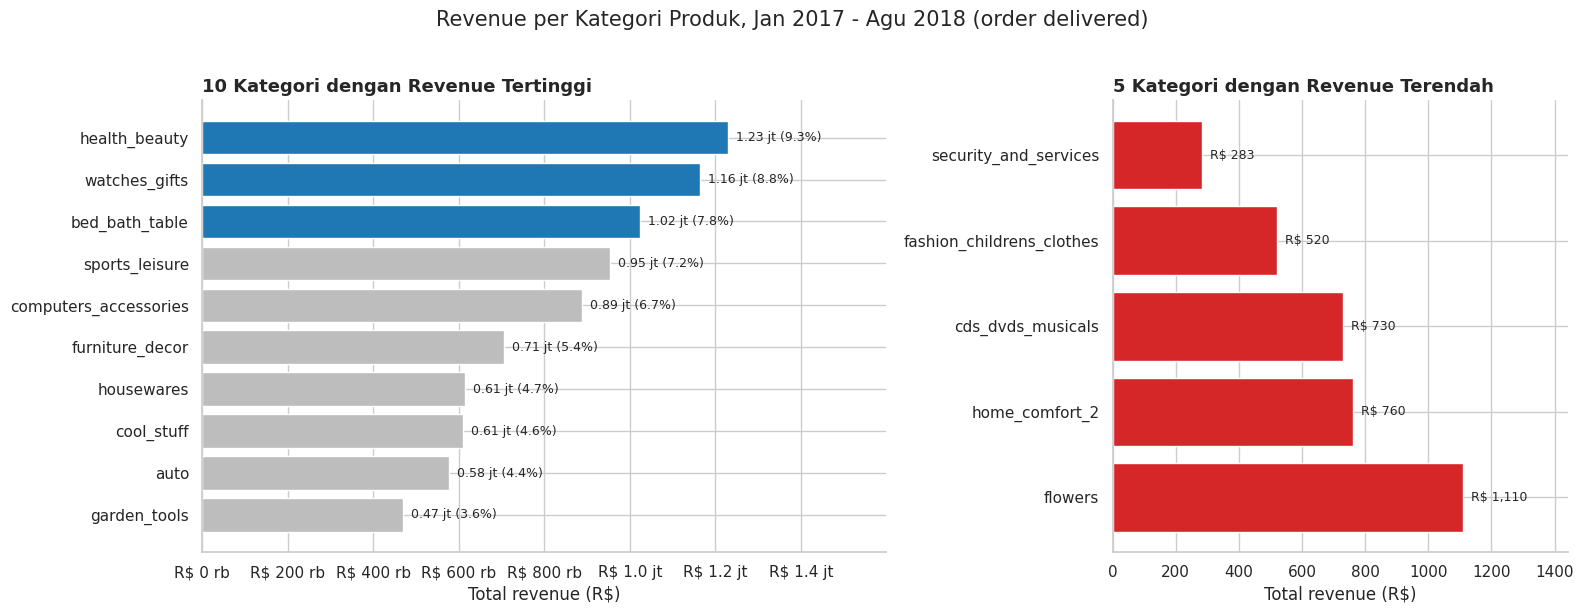

In [29]:
top10 = category_perf.head(10).sort_values("revenue")
bottom5 = category_perf.tail(5).sort_values("revenue", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.5, 1]})

colors = [HIGHLIGHT if i >= 7 else MUTED for i in range(10)]
axes[0].barh(top10.index, top10["revenue"], color=colors)
for y, (rev, pct) in enumerate(zip(top10["revenue"], top10["pct_revenue"])):
    axes[0].text(rev, y, f"  {rev/1e6:.2f} jt ({pct:.1f}%)", va="center", fontsize=9)
axes[0].set_title("10 Kategori dengan Revenue Tertinggi", fontsize=13, loc="left", fontweight="bold")
axes[0].xaxis.set_major_formatter(FuncFormatter(currency_fmt))
axes[0].set_xlim(0, top10["revenue"].max() * 1.3)
axes[0].set_xlabel("Total revenue (R$)"); axes[0].set_ylabel("")

axes[1].barh(bottom5.index, bottom5["revenue"], color=ALERT)
for y, rev in enumerate(bottom5["revenue"]):
    axes[1].text(rev, y, f"  R$ {rev:,.0f}", va="center", fontsize=9)
axes[1].set_title("5 Kategori dengan Revenue Terendah", fontsize=13, loc="left", fontweight="bold")
axes[1].set_xlim(0, bottom5["revenue"].max() * 1.3)
axes[1].set_xlabel("Total revenue (R$)"); axes[1].set_ylabel("")

fig.suptitle("Revenue per Kategori Produk, Jan 2017 - Agu 2018 (order delivered)", fontsize=15, y=1.02)
sns.despine(); plt.tight_layout(); plt.show()

**Insight:**
- Tiga kategori teratas (biru) adalah `health_beauty`, `watches_gifts`, dan `bed_bath_table`; sepuluh kategori teratas bersama-sama menyumbang sekitar 62% revenue.
- Kategori terbawah (merah) hanya menghasilkan ratusan Real per kategori, kurang dari 0,01% revenue.

### Pertanyaan 2: Bagaimana tren order dan revenue bulanan, dan kapan puncaknya?
**Tujuan visualisasi:** kombinasi *bar chart* (revenue) dan *line chart* (order) karena data berurutan waktu dan keduanya bergerak searah. Sumbu revenue dimulai dari nol, dan bulan puncak diberi anotasi langsung.

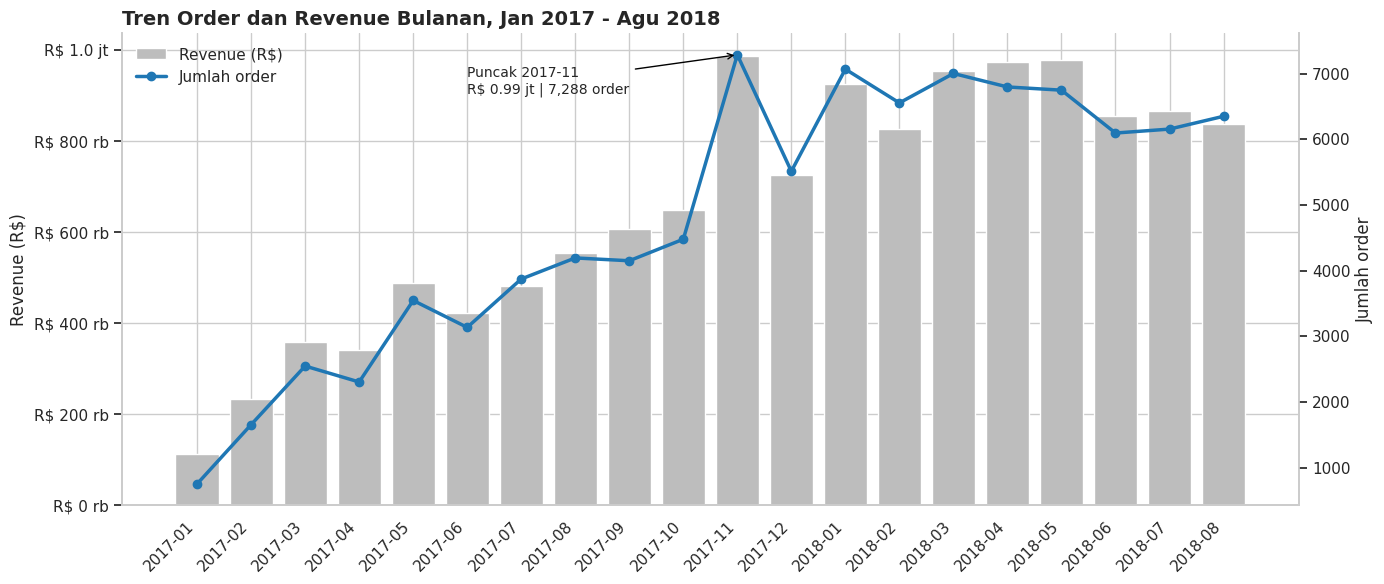

In [30]:
fig, ax1 = plt.subplots(figsize=(14, 6))
x = np.arange(len(monthly))
ax1.bar(x, monthly["revenue"], color=MUTED, label="Revenue (R$)")
ax1.set_ylabel("Revenue (R$)")
ax1.yaxis.set_major_formatter(FuncFormatter(currency_fmt))
ax1.set_xticks(x); ax1.set_xticklabels(monthly.index, rotation=45, ha="right")

ax2 = ax1.twinx()
ax2.plot(x, monthly["orders"], color=HIGHLIGHT, marker="o", linewidth=2.5, label="Jumlah order")
ax2.set_ylabel("Jumlah order"); ax2.grid(False)

peak = monthly["revenue"].idxmax(); px = list(monthly.index).index(peak)
ax2.annotate(f"Puncak {peak}\nR$ {monthly.loc[peak, 'revenue']/1e6:.2f} jt | {monthly.loc[peak, 'orders']:,} order",
             xy=(px, monthly.loc[peak, "orders"]), xytext=(px - 5, monthly["orders"].max() * 0.92),
             arrowprops=dict(arrowstyle="->", color="black"), fontsize=10)

h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", frameon=False)
ax1.set_title("Tren Order dan Revenue Bulanan, Jan 2017 - Agu 2018", fontsize=14, loc="left", fontweight="bold")
sns.despine(right=False); plt.tight_layout(); plt.show()

**Insight:**
- Batang abu-abu (revenue) dan garis biru (order) naik hampir sejajar sepanjang 2017, lalu melonjak ke puncak pada **November 2017**.
- Setelah Desember 2017 turun, 2018 bergerak mendatar tanpa pertumbuhan berarti, sehingga pertumbuhan 2018 terutama berasal dari basis yang sudah besar di akhir 2017.

### Pertanyaan 3: State mana yang menyumbang revenue terbesar, dan bagaimana keterlambatan serta review-nya?
**Tujuan visualisasi:** tiga *bar chart* berdampingan dengan urutan state yang sama agar revenue, keterlambatan, dan kepuasan mudah dibandingkan; garis putus-putus menandai rata-rata keseluruhan dan warna merah menyoroti state di atas rata-rata. Sumbu review dimulai dari nol agar perbedaan tidak dilebih-lebihkan. *Bar chart* kedua dipakai untuk hasil binning keterlambatan.

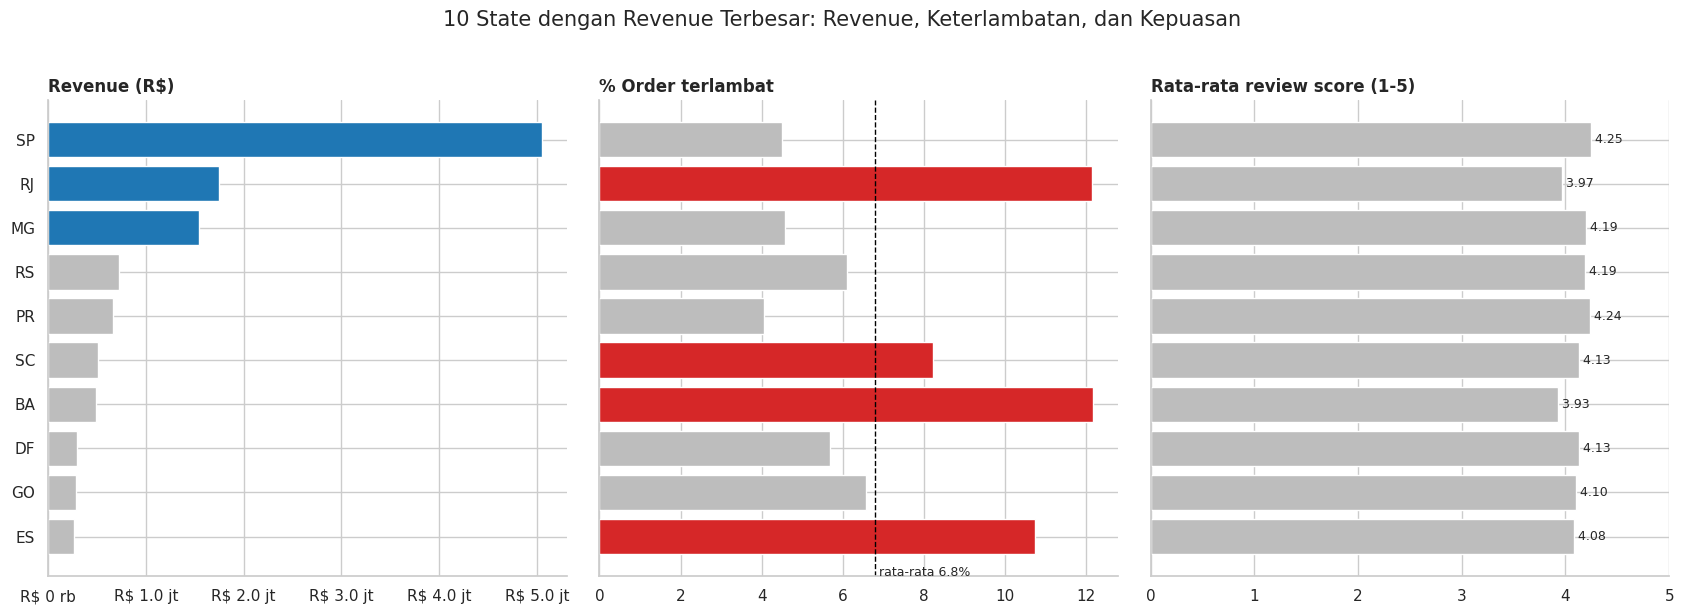

In [31]:
top_states = state_perf.head(10).sort_values("revenue")
fig, axes = plt.subplots(1, 3, figsize=(17, 6), sharey=True)

axes[0].barh(top_states.index, top_states["revenue"], color=[HIGHLIGHT if s in ("SP", "RJ", "MG") else MUTED for s in top_states.index])
axes[0].set_title("Revenue (R$)", loc="left", fontweight="bold"); axes[0].xaxis.set_major_formatter(FuncFormatter(currency_fmt))

avg_late = order_level["is_late"].mean() * 100
axes[1].barh(top_states.index, top_states["late_pct"], color=[ALERT if v > avg_late else MUTED for v in top_states["late_pct"]])
axes[1].axvline(avg_late, color="black", linestyle="--", linewidth=1)
axes[1].text(avg_late, -0.9, f" rata-rata {avg_late:.1f}%", fontsize=9)
axes[1].set_title("% Order terlambat", loc="left", fontweight="bold")

axes[2].barh(top_states.index, top_states["avg_review"], color=MUTED)
axes[2].set_xlim(0, 5)
for y, v in enumerate(top_states["avg_review"]):
    axes[2].text(v, y, f" {v:.2f}", va="center", fontsize=9)
axes[2].set_title("Rata-rata review score (1-5)", loc="left", fontweight="bold")

fig.suptitle("10 State dengan Revenue Terbesar: Revenue, Keterlambatan, dan Kepuasan", fontsize=15, y=1.02)
sns.despine(); plt.tight_layout(); plt.show()

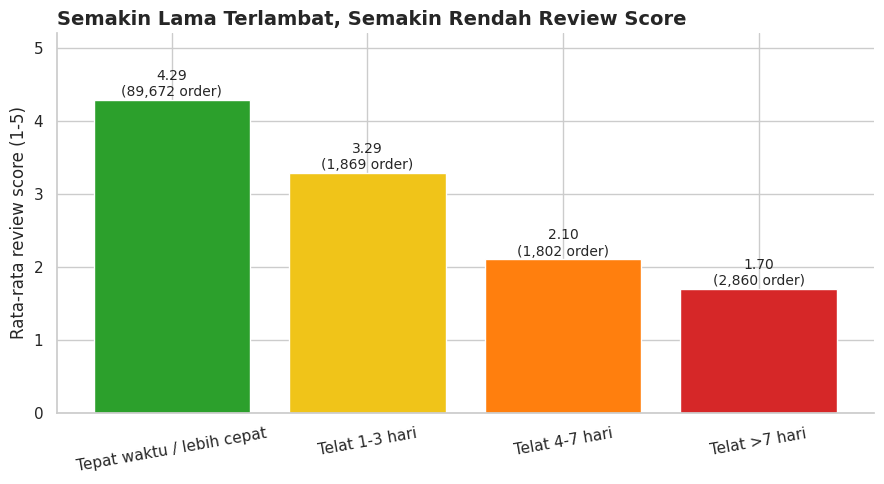

In [32]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#2ca02c", "#f0c419", "#ff7f0e", ALERT]
bars = ax.bar(delay_review.index.astype(str), delay_review["avg_review"], color=colors)
for b, (rv, n) in zip(bars, zip(delay_review["avg_review"], delay_review["orders"])):
    ax.text(b.get_x() + b.get_width() / 2, rv + 0.05, f"{rv:.2f}\n({n:,} order)", ha="center", fontsize=10)
ax.set_ylim(0, 5.2); ax.set_ylabel("Rata-rata review score (1-5)")
ax.set_title("Semakin Lama Terlambat, Semakin Rendah Review Score", loc="left", fontsize=14, fontweight="bold")
plt.xticks(rotation=10); sns.despine(); plt.tight_layout(); plt.show()

**Insight:**
- SP, RJ, dan MG (biru) mendominasi revenue. Namun RJ memiliki 12,1% order terlambat (rata-rata 6,8%) dan review 3,97, lebih rendah dibanding SP (4,25) dan MG (4,19).
- Order tepat waktu mendapat review rata-rata 4,29, sedangkan keterlambatan lebih dari 7 hari turun drastis menjadi 1,70. Ini hubungan, bukan bukti sebab-akibat.

### Pertanyaan 4: Bagaimana segmentasi pelanggan berdasarkan RFM?
**Tujuan visualisasi:** dua *bar chart* berdampingan (% pelanggan vs % revenue) dengan urutan segmen yang sama, sehingga terlihat segmen kecil yang menyumbang revenue besar. Warna konsisten per segmen.

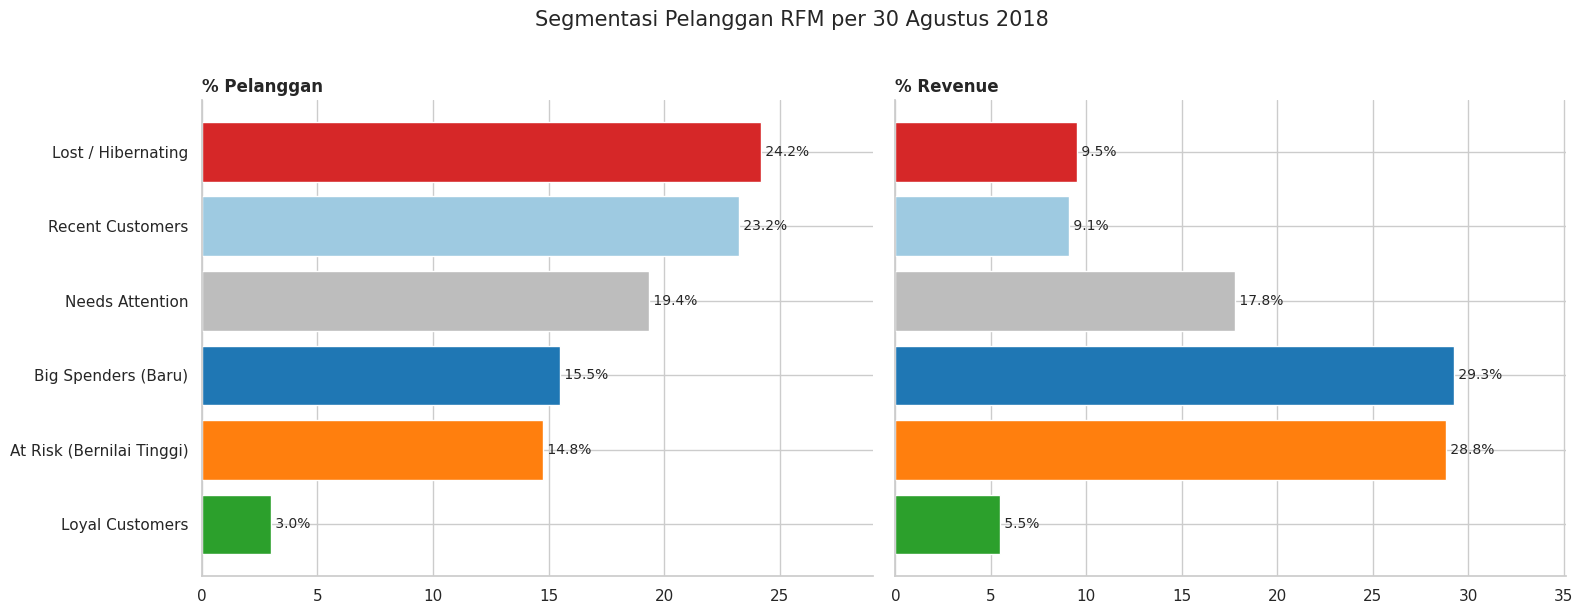

In [33]:
seg_order = segment_perf.sort_values("customers", ascending=True)
seg_colors = {"Loyal Customers": "#2ca02c", "Big Spenders (Baru)": HIGHLIGHT, "Recent Customers": "#9ecae1",
              "Needs Attention": MUTED, "At Risk (Bernilai Tinggi)": "#ff7f0e", "Lost / Hibernating": ALERT}

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
axes[0].barh(seg_order.index, seg_order["pct_customers"], color=[seg_colors[s] for s in seg_order.index])
for y, v in enumerate(seg_order["pct_customers"]):
    axes[0].text(v, y, f" {v:.1f}%", va="center", fontsize=10)
axes[0].set_title("% Pelanggan", loc="left", fontweight="bold"); axes[0].set_xlim(0, seg_order["pct_customers"].max() * 1.2)

axes[1].barh(seg_order.index, seg_order["pct_revenue"], color=[seg_colors[s] for s in seg_order.index])
for y, v in enumerate(seg_order["pct_revenue"]):
    axes[1].text(v, y, f" {v:.1f}%", va="center", fontsize=10)
axes[1].set_title("% Revenue", loc="left", fontweight="bold"); axes[1].set_xlim(0, seg_order["pct_revenue"].max() * 1.2)

fig.suptitle("Segmentasi Pelanggan RFM per 30 Agustus 2018", fontsize=15, y=1.02)
sns.despine(); plt.tight_layout(); plt.show()

**Insight:**
- Loyal Customers (hijau) kecil, hanya 3,0% pelanggan dan 5,5% revenue.
- Big Spenders (Baru) dan At Risk (Bernilai Tinggi) memiliki porsi pelanggan sedang (±15%) tetapi porsi revenue terbesar (±29% masing-masing). Segmen At Risk adalah peluang reaktivasi bernilai tinggi.

## Analisis Lanjutan (Opsional)

Teknik analisis lanjutan yang diterapkan, seluruhnya **tanpa algoritma machine learning**:
1. **RFM Analysis** (Pertanyaan 4): mengelompokkan pelanggan berdasarkan Recency, Frequency, dan Monetary untuk menentukan target kampanye retensi dan reaktivasi.
2. **Clustering dengan Manual Grouping dan Binning**: segmen RFM dibuat dengan aturan bisnis (*manual grouping*), dan keterlambatan pengiriman dikelompokkan ke dalam interval (*binning*) pada Pertanyaan 3.
3. **Geospatial Analysis** (di bawah): memetakan sebaran revenue berdasarkan koordinat kode pos pelanggan untuk melihat konsentrasi wilayah dan area dengan kepadatan rendah.

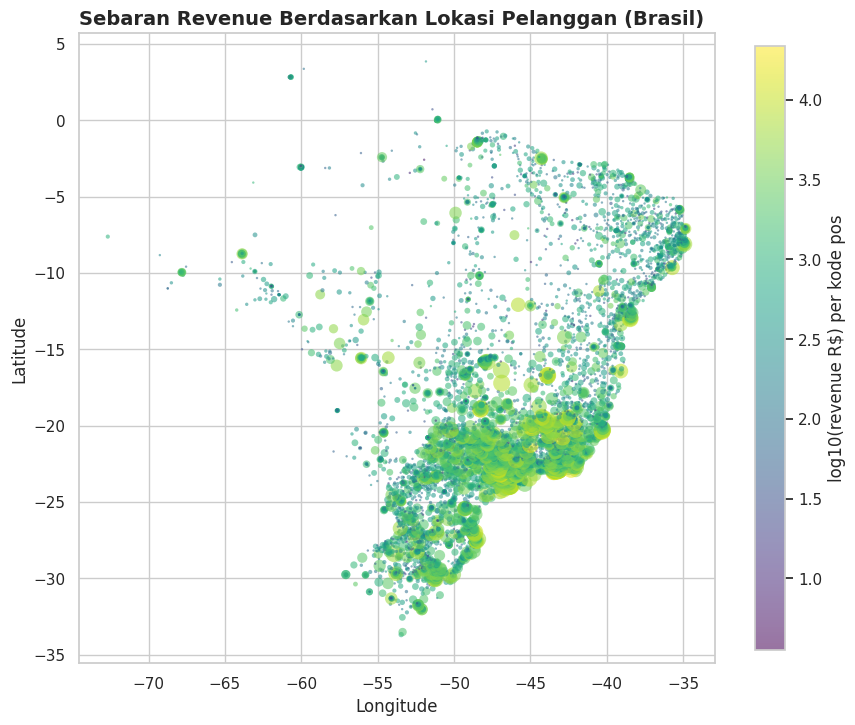

In [34]:
geo_plot = (main_df.dropna(subset=["lat", "lng"])
            .groupby(["lat", "lng"], as_index=False)
            .agg(revenue=("price", "sum"), orders=("order_id", "nunique")))

fig, ax = plt.subplots(figsize=(9, 9))
sc = ax.scatter(geo_plot["lng"], geo_plot["lat"], s=np.clip(geo_plot["orders"] * 3, 3, 150),
                c=np.log10(geo_plot["revenue"]), cmap="viridis", alpha=0.55, linewidths=0)
cb = plt.colorbar(sc, shrink=0.7); cb.set_label("log10(revenue R$) per kode pos")
ax.set_title("Sebaran Revenue Berdasarkan Lokasi Pelanggan (Brasil)", loc="left", fontsize=14, fontweight="bold")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

In [35]:
# Rencana tindakan per segmen RFM
strategi = pd.DataFrame({
    "segment": ["Big Spenders (Baru)", "Recent Customers", "At Risk (Bernilai Tinggi)",
                "Lost / Hibernating", "Needs Attention", "Loyal Customers"],
    "tindakan": ["Voucher repeat order sebelum menjadi dormant", "Rekomendasi produk dan promo order kedua",
                 "Kampanye reaktivasi personal dengan penawaran khusus", "Kampanye biaya rendah (email/notifikasi)",
                 "Pengingat dan promo musiman", "Program loyalitas dan akses awal promo"]
}).merge(segment_perf[["customers", "pct_customers", "pct_revenue"]].reset_index(), on="segment")
strategi.round(1)

,segment,tindakan,customers,pct_customers,pct_revenue
0,Big Spenders (Baru),Voucher repeat order sebelum menjadi dormant,14438,15.5,29.3
1,Recent Customers,Rekomendasi produk dan promo order kedua,21605,23.2,9.1
2,At Risk (Bernilai Tinggi),Kampanye reaktivasi personal dengan penawaran ...,13744,14.8,28.8
3,Lost / Hibernating,Kampanye biaya rendah (email/notifikasi),22499,24.2,9.5
4,Needs Attention,Pengingat dan promo musiman,18021,19.4,17.8
5,Loyal Customers,Program loyalitas dan akses awal promo,2789,3.0,5.5


**Insight:**
- Peta menunjukkan pelanggan terkonsentrasi di wilayah Tenggara dan Selatan Brasil (sekitar São Paulo, Rio de Janeiro, dan Minas Gerais), dengan titik-titik yang jarang di Utara. Ini konsisten dengan dominasi SP, RJ, dan MG pada revenue.
- Wilayah yang jarang tetapi bermasalah di pengiriman (Timur Laut) memiliki volume kecil, sehingga perbaikan logistik di sana perlu dihitung manfaatnya terhadap kepuasan, bukan terhadap revenue.
- Tabel tindakan menghubungkan setiap segmen RFM dengan langkah kampanye yang konkret.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** `health_beauty` (9,3%), `watches_gifts` (8,8%), dan `bed_bath_table` (7,8%) adalah tiga kategori dengan revenue terbesar, dan 10 kategori teratas menyumbang sekitar 62% total revenue selama Jan 2017 – Agu 2018. Kategori seperti `security_and_services`, `fashion_childrens_clothes`, dan `cds_dvds_musicals` hampir tidak berkontribusi (< 0,01%).
- **Conclusion pertanyaan 2:** Revenue dan order tumbuh pesat sepanjang 2017 dengan puncak pada November 2017 (R$ 0,99 juta, 7.288 order, MoM +52,4%), lalu turun 26,5% pada Desember 2017 dan stagnan pada 2018 di kisaran R$ 0,83–0,98 juta per bulan.
- **Conclusion pertanyaan 3:** SP, RJ, dan MG menyumbang 63,4% revenue. RJ (12,1%) dan state Timur Laut seperti AL (21,5%), MA (17,5%), SE (15,4%), dan PI (13,9%) memiliki persentase keterlambatan jauh di atas rata-rata keseluruhan (6,8%). Keterlambatan berkaitan dengan kepuasan: review turun dari 4,29 (tepat waktu) menjadi 1,70 (telat lebih dari 7 hari). Ini hubungan, bukan bukti sebab-akibat.
- **Conclusion pertanyaan 4:** Sekitar 97% pelanggan hanya membeli satu kali. Pelanggan loyal (≥ 2 order) hanya 3,0% (5,5% revenue), sedangkan Big Spenders (Baru) dan At Risk (Bernilai Tinggi) menyumbang sekitar 58% revenue, dan sekitar 39% pelanggan sudah dormant lebih dari setahun.

**Rekomendasi Action Item:**
- **Prioritaskan stok, iklan, dan promosi** pada kategori `health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, dan `computers_accessories`; evaluasi atau rampingkan kategori dengan kontribusi hampir nol.
- **Siapkan kampanye dan kapasitas gudang/kurir mulai Oktober** untuk menghadapi lonjakan November, serta rencanakan program pemicu pertumbuhan karena revenue 2018 cenderung mendatar.
- **Perbaiki logistik di RJ** (volume besar, keterlambatan tinggi) dan evaluasi estimasi pengiriman atau mitra kurir di AL, MA, dan PI; pasang peringatan dini untuk order yang berpotensi terlambat lebih dari 3 hari.
- **Jalankan kampanye retensi**: voucher repeat order untuk Recent Customers dan Big Spenders (Baru), kampanye reaktivasi untuk At Risk (Bernilai Tinggi, penyumbang 28,8% revenue), dan program loyalitas bagi Loyal Customers.